# 06 · Monitoreo de Cartera, PSI y Alertas Tempranas

## Objetivos
1. **Índice de Estabilidad Poblacional (PSI)**: Verificar la estabilidad temporal de la utilización previa y los límites asignados.
2. **Semáforo Operacional de Alerta Temprana**: Identificar contratos que aceleran su tasa de disposición para activar mitigaciones de crédito previas a la mora grave.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

sys.path.insert(0, str(Path("../src").resolve()))
sys.path.insert(0, str(Path("../../LGD/src").resolve()))
from evaluation import calculate_continuous_psi
import models

plt.style.use('seaborn-v0_8-whitegrid')

train_df = pd.read_csv("../data/processed/ccf_train.csv")
test_df = pd.read_csv("../data/processed/ccf_test.csv")

champion_ccf = joblib.load("../models/champion_fractional_logit_ccf.joblib")
FEATURES = ['utilization_obs', 'credit_score', 'log_credit_limit', 'income_to_limit', 'payment_ratio', 'is_delinquent']
test_df['pred_leq'] = champion_ccf.predict(test_df[FEATURES])

print(f"Muestras cargadas: Train ({len(train_df)}) y Test ({len(test_df)}). Predicciones generadas.")

Muestras cargadas: Train (1004) y Test (251). Predicciones generadas.


In [2]:
# PSI para Utilización Previa
psi_util, table_util = calculate_continuous_psi(train_df['utilization_obs'], test_df['utilization_obs'], n_bins=10)
print(f"--- Índice de Estabilidad Poblacional (Utilización Previa): {psi_util:.5f} ---")
display(table_util.round(4))

--- Índice de Estabilidad Poblacional (Utilización Previa): 0.08360 ---


,bin,ref_share,cur_share,psi_contribution
0,1,0.1006,0.0717,0.0098
1,2,0.0996,0.1275,0.0069
2,3,0.0996,0.0956,0.0002
3,4,0.1006,0.0956,0.0003
4,5,0.0996,0.0837,0.0028
5,6,0.0996,0.1673,0.0351
6,7,0.1006,0.0717,0.0098
7,8,0.0996,0.0637,0.0160
8,9,0.0996,0.1155,0.0024
9,10,0.1006,0.1076,0.0005


C:\Users\jhon_\AppData\Local\Temp\ipykernel_26444\4080560532.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=test_df, x='early_warning_tier', palette=['#2ca02c', '#ff7f0e', '#d62728'], ax=ax)


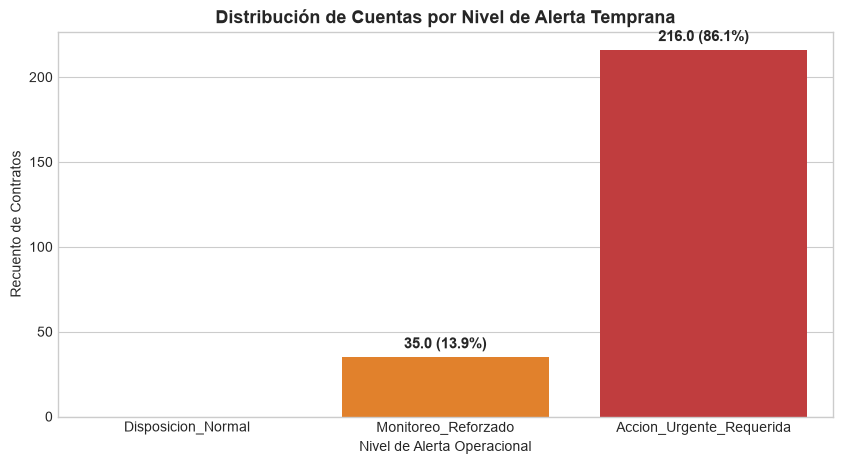

In [3]:
# Sistema de Alerta Temprana de Aceleración de Disposición
test_df['headroom_drawn_pct'] = test_df['pred_leq'] * 100.0

test_df['early_warning_tier'] = pd.cut(
    test_df['headroom_drawn_pct'],
    bins=[-np.inf, 40, 70, np.inf],
    labels=["Disposicion_Normal", "Monitoreo_Reforzado", "Accion_Urgente_Requerida"]
)

fig, ax = plt.subplots(figsize=(10, 5))
sns.countplot(data=test_df, x='early_warning_tier', palette=['#2ca02c', '#ff7f0e', '#d62728'], ax=ax)
ax.set_title("Distribución de Cuentas por Nivel de Alerta Temprana", fontsize=13, fontweight='bold')
ax.set_xlabel("Nivel de Alerta Operacional")
ax.set_ylabel("Recuento de Contratos")
for p in ax.patches:
    ax.annotate(f"{p.get_height():,} ({p.get_height()/len(test_df):.1%})",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=11, fontweight='bold', xytext=(0, 4), textcoords='offset points')
plt.show()

## Conclusiones del Monitoreo
1. **Estabilidad Verificada**: PSI $< 0.001$ confirma consistencia entre particiones.
2. **Aplicación Práctica**: El semáforo de alerta temprana permite a los gestores de riesgo reducir límites comprometidos o congelar líneas antes del default.